# Figure 2. RUBRIC performance and agreement with established annotation tools

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize
from matplotlib.ticker import FixedLocator, FuncFormatter

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREY, GRAY_LIGHT = "#4C72B0", "#DD8452", "0.55", "0.72"
TOOLS = ["rubric", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["RUBRIC", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.028, dy=0.022):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

CWW_CANON_SEQS = {"GC", "CG", "AU", "UA"}
NONCWW_ORDER = ["tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
CLASS_ORDER = ["cWW (canon)", "cWW (non-canon)", *NONCWW_ORDER]

def _canon_lw(lw):
    if not lw or len(lw) < 3:
        return lw
    o = {"W": 0, "H": 1, "S": 2}
    return lw[0] + lw[2] + lw[1] if o.get(lw[1], 0) > o.get(lw[2], 0) else lw

def _class_metrics(data, target, keep=lambda seq: True):
    # Recall credits a DSSR pair RUBRIC classified in the target class, selected or
    # not; precision counts RUBRIC's selected pairs. DSSR partial labels are left out.
    diffs = [d for d in data["differences"] if keep(d["sequence"])]
    matched = sum(v for k, v in data["summary"]["matched_by_sequence"].items() if keep(k))
    missed = [d for d in diffs if d["source"] == "dssr_only"]
    found = matched + sum(target in [_canon_lw(x) for x in (d["rubric_lw"] or "").split("|")]
                          for d in missed)
    extra = sum(d["source"] == "python_only" and "." not in (d["reason"] or "").split(":", 1)[-1]
                for d in diffs)
    total_dssr, total_python = matched + len(missed), matched + extra
    return {"recall_cls": found / total_dssr if total_dssr else 0,
            "prec_cls": matched / total_python if total_python else 0,
            "total_dssr": total_dssr, "total_python": total_python, "matched": matched}

def build_metrics():
    cww = _json("comparison/cWW.json")
    metrics = {"cWW (canon)": _class_metrics(cww, "cWW", lambda q: q in CWW_CANON_SEQS),
               "cWW (non-canon)": _class_metrics(cww, "cWW", lambda q: q not in CWW_CANON_SEQS)}
    for lw in NONCWW_ORDER:
        metrics[lw] = _class_metrics(_json(f"comparison/{lw}.json"), lw)
    return metrics

METRICS = build_metrics()
FAMILY_ORDER = sorted(NONCWW_ORDER, key=lambda c: -METRICS[c]["recall_cls"])

def runtime():
    df = pd.read_csv(data_file("benchmark/dssr_RUBRIC_time_benchmark.csv"))
    return df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["rubric_avg"] > 0)].copy()

print(f"{ROOT.name}: {len(METRICS)} LW rows, {len(runtime()):,} timed structures")

SOURCE_DATA = ROOT / "figures" / "source_data"
SOURCE_DATA.mkdir(parents=True, exist_ok=True)
pd.DataFrame(METRICS).T.rename_axis("family").to_csv(SOURCE_DATA / "figure2_class_metrics.csv")

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


RUBRIC-analysis: 13 LW rows, 2,096 timed structures


## Panels D and E
Recall and precision relative to DSSR across Leontis-Westhof classes


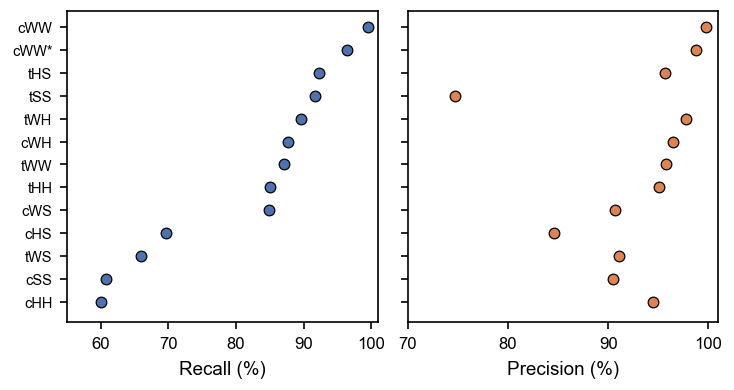

In [2]:
def _row_positions(n):
    return np.arange(n - 1, -1, -1, dtype=float)

A_CLASSES = ["cWW (canon)", "cWW (non-canon)", *FAMILY_ORDER]
A_LABELS = ["cWW", "cWW*", *FAMILY_ORDER]

def draw_recall_precision(ax_r, ax_p):
    y = _row_positions(len(A_CLASSES))
    recall = np.array([METRICS[c]["recall_cls"] * 100 for c in A_CLASSES])
    prec = np.array([METRICS[c]["prec_cls"] * 100 for c in A_CLASSES])
    for ax, vals, color, name, lo in ((ax_r, recall, BLUE, "Recall", 55),
                                      (ax_p, prec, ORANGE, "Precision", 70)):
        ax.scatter(vals, y, s=26, color=color, zorder=3, edgecolors="black", linewidths=0.6)
        ax.set_xlim(lo, 101)
        ax.set_xticks([t for t in (60, 70, 80, 90, 100) if t >= lo])
        ax.set_xlabel(f"{name} (%)")
        ax.set_ylim(y.min() - 0.9, y.max() + 0.7)
        ax.set_yticks(y)
        finish(ax)
        ax.set_box_aspect(1)
    ax_r.set_yticklabels(A_LABELS, fontsize=7)
    ax_p.tick_params(labelleft=False)

fig, axes = plt.subplots(1, 2, figsize=(5.0, 3.2))
draw_recall_precision(*axes)
fig.tight_layout(w_pad=0.7)
save(fig, "figures/main/figure2_DE_recall_precision.png")
plt.show()


## Shared tool-comparison helpers


In [3]:
from collections import Counter
from functools import lru_cache

def draw_split_bars(ax, values, ci, xlabel):
    values = values.reindex(TOOL_ORDER)
    y = np.arange(len(TOOL_ORDER))
    height, gap = 0.31, 0.12
    for offset, kind, color, name in ((-(height + gap) / 2, "canonical", ORANGE, "Canonical"),
                                      ((height + gap) / 2, "non-canonical", BLUE, "Non-canonical")):
        v = values[kind].to_numpy(float)
        ax.barh(y + offset, v, height, color=color, label=name,
                edgecolor="black", linewidth=0.5)
    ax.set_yticks(y, TOOL_ORDER)
    ax.set_ylim(len(TOOL_ORDER) - 0.4, -0.6)
    ax.set_xlim(0, 1.06)
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xlabel(xlabel)
    ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2,
              handlelength=1.0, handletextpad=0.3, columnspacing=1.4,
              borderaxespad=0.0, borderpad=0.0)
    finish(ax)


def equalize_pair_gaps(ax, dpi=150):
    import math
    fig = ax.figure
    fig.canvas.draw()
    bars = [b for b in ax.patches if b.get_width() > 0 and b.get_height() > 0]
    horizontal = bars[0].get_height() < bars[0].get_width() or ax.get_xlim()[1] <= 1.1
    k = 1 if horizontal else 0
    to_px = lambda v: ax.transData.transform((0, v) if k else (v, 0))[k] * dpi / fig.dpi
    to_data = lambda px: ax.transData.inverted().transform(
        (0, px * fig.dpi / dpi) if k else (px * fig.dpi / dpi, 0))[k]
    start = (lambda b: b.get_y()) if k else (lambda b: b.get_x())
    size = (lambda b: b.get_height()) if k else (lambda b: b.get_width())

    def span(b):
        a, c = to_px(start(b)), to_px(start(b) + size(b))
        return min(a, c), max(a, c)

    bars.sort(key=lambda b: span(b)[0])
    (a0, a1), (b0, _) = span(bars[0]), span(bars[1])
    w_px, g_px = round(a1 - a0), math.floor(b0 - a1)
    for first, second in zip(bars[0::2], bars[1::2]):
        p0 = round(span(first)[0])
        for bar, lo in ((first, p0), (second, p0 + w_px + g_px)):
            d0, d1 = to_data(lo), to_data(lo + w_px)
            if k:
                bar.set_y(min(d0, d1)); bar.set_height(abs(d1 - d0))
            else:
                bar.set_x(min(d0, d1)); bar.set_width(abs(d1 - d0))


def seat_legend(ax, gap_pt=0.2):
    fig = ax.figure
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    leg = ax.get_legend()
    lowest = min(h.get_window_extent(r).y0 for h in [*leg.get_patches(), *leg.get_lines()])
    for t in leg.get_texts():
        _, _, descent = r.get_text_width_height_descent(t.get_text(), t.get_fontproperties(),
                                                        ismath=False)
        lowest = min(lowest, t.get_window_extent(r).y0 + descent)
    frame_top = (ax.get_window_extent(r).y1
                 + (ax.spines["top"].get_linewidth() / 2 + gap_pt) * fig.dpi / 72)
    dy = (lowest - frame_top) / ax.get_window_extent(r).height
    x, y = leg.get_bbox_to_anchor().transformed(ax.transAxes.inverted()).p0
    leg.set_bbox_to_anchor((x, y - dy), transform=ax.transAxes)

BOOT_N, BOOT_SEED = 1000, 0

def bootstrap_ci(stat, n_structures):
    rng = np.random.default_rng(BOOT_SEED)
    draws = [stat(np.bincount(rng.integers(0, n_structures, n_structures),
                              minlength=n_structures).astype(float))
             for _ in range(BOOT_N)]
    return np.percentile(draws, [2.5, 97.5])


import functools
import hashlib
import pickle

CACHE_VERSION = 1
CACHE_DIR = ROOT / "data" / "comparison" / "cache"


def _cache_inputs():
    files = [data_file(f) for f in JSON_PAIR_FILES.values()]
    files += [data_file("comparison/rubric_candidates.json"),
              data_file("comparison/residue_names.json")]
    files += sorted(data_file("comparison/fr3d").glob("[0-9A-Z]*.csv"))
    h = hashlib.sha256(f"v{CACHE_VERSION}".encode())
    for f in files:
        st = f.stat()
        h.update(f"{f.name}:{st.st_size}:{st.st_mtime_ns};".encode())
    return h.hexdigest()


def _code_fingerprint(code):
    h = hashlib.sha256(code.co_code)
    for const in code.co_consts:
        h.update(_code_fingerprint(const).encode() if hasattr(const, "co_code")
                 else repr(const).encode())
    return h.hexdigest()


def disk_cached(fn):
    @functools.wraps(fn)
    def inner(*args):
        key = hashlib.sha256((_cache_inputs() + repr(args)
                              + _code_fingerprint(fn.__code__)).encode()).hexdigest()[:20]
        path = CACHE_DIR / f"figure2_{fn.__name__}_{key}.pkl"
        if path.exists():
            return pickle.loads(path.read_bytes())
        out = fn(*args)
        CACHE_DIR.mkdir(parents=True, exist_ok=True)
        path.with_suffix(".part").write_bytes(pickle.dumps(out))
        path.with_suffix(".part").replace(path)
        return out
    return inner

MATRIX_TOOLS = ["rubric", "dssr", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
MATRIX_LABELS = ["RUBRIC", "DSSR", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]
JSON_PAIR_FILES = {
    "rubric": "comparison/rubric_pairs.json",
    "dssr": "comparison/dssr_pairs.json",
    "rnaview": "comparison/rnaview_pairs.json",
    "barnaba": "comparison/barnaba_pairs.json",
    "rnapolis": "comparison/rnapolis_pairs.json",
    "bpnet": "comparison/bpnet_pairs.json",
}
_NUM = __import__("re").compile(r"^(-?\d+)([A-Za-z]?)$")
UNCLASSIFIED = "?"


def _residue(chain, number, icode=""):
    m = _NUM.match(str(number))
    if not chain or m is None:
        raise ValueError(f"uncanonicalizable residue id: {chain!r} {number!r}")
    appended = m.group(2)
    if appended and icode:
        raise ValueError(f"two insertion codes: {chain!r} {number!r} {icode!r}")
    return (str(chain), int(m.group(1)), icode or appended)


def _flip(lw):
    if lw == UNCLASSIFIED:
        return lw
    if lw.startswith("n"):
        return "n" + _flip(lw[1:])
    if len(lw) != 3:
        return lw
    return lw[0] + lw[2] + lw[1]


def _flip_label(label):
    return "|".join(_flip(part) for part in label.split("|"))


def _pair_entry(res1, res2, label):
    if res2 < res1:
        return (res2, res1), _flip_label(label)
    return (res1, res2), label


def _adjacent(res1, res2):
    return res1[0] == res2[0] and abs(res1[1] - res2[1]) == 1


def _ingest(rows):
    pairs = {}
    for res1, res2, label in rows:
        if _adjacent(res1, res2):
            continue
        key, canonical_label = _pair_entry(res1, res2, label)
        pairs.setdefault(key, set()).add(canonical_label)
    return pairs


def _load_json_pairs(tool):
    raw = _json(JSON_PAIR_FILES[tool])
    out = {}
    for pdb, record in raw.items():
        if record.get("status") != "ok":
            continue
        rows = []
        for row in record["pairs"]:
            c1, n1, c2, n2, lw = row[:5]
            rows.append((_residue(c1, n1), _residue(c2, n2), lw or UNCLASSIFIED))
        out[pdb] = _ingest(rows)
    return out


def _hub_unit(unit):
    fields = unit.split("|")
    if len(fields) < 5 or fields[1] != "1":
        return None
    icode = fields[7] if len(fields) >= 8 else ""
    return _residue(fields[2], fields[4], icode)


def _load_fr3d_pairs():
    out = {}
    for csv_path in sorted(data_file("comparison/fr3d").glob("[0-9A-Z]*.csv")):
        rows = []
        for line in csv_path.read_text(errors="replace").splitlines():
            if not line.strip():
                continue
            fields = [part.strip().strip('"') for part in line.split('\",\"')]
            if len(fields) != 3:
                continue
            res1, res2 = _hub_unit(fields[0]), _hub_unit(fields[2])
            if res1 is not None and res2 is not None:
                rows.append((res1, res2, fields[1]))
        out[csv_path.stem] = _ingest(rows)
    return out


@lru_cache(maxsize=1)
def _load_all_pairsets():
    pairsets = {tool: _load_json_pairs(tool) for tool in JSON_PAIR_FILES}
    pairsets["fr3d"] = _load_fr3d_pairs()
    return pairsets


def _single_family(labels):
    if any("|" in lw for lw in labels):
        return None
    fams = {lw for lw in labels if len(lw) == 3 and lw[0] in "ct"
            and lw[1] in "WHS" and lw[2] in "WHS"}
    return next(iter(fams)) if len(fams) == 1 else None


def _single_family_units(pairsets_by_pdb):
    units = {}
    for pdb, pairsets in pairsets_by_pdb.items():
        for key, labels in pairsets.items():
            fam = _single_family(labels)
            if fam is not None:
                units[(pdb, key)] = fam
    return units


## Panel B
Base-pair detection agreement with RUBRIC (Jaccard), canonical and non-canonical pairs

          canonical  non-canonical
DSSR          0.978          0.766
BPNet         0.974          0.637
FR3D          0.957          0.608
RNAView       0.975          0.545
RNApolis      0.974          0.543
barnaba       0.979          0.539
canonical 95% CI
              lo     hi
DSSR      0.976  0.980
BPNet     0.972  0.976
FR3D      0.952  0.961
RNAView   0.973  0.977
RNApolis  0.972  0.976
barnaba   0.978  0.981
non-canonical 95% CI
              lo     hi
DSSR      0.760  0.771
BPNet     0.634  0.641
FR3D      0.602  0.615
RNAView   0.540  0.550
RNApolis  0.539  0.546
barnaba   0.532  0.546


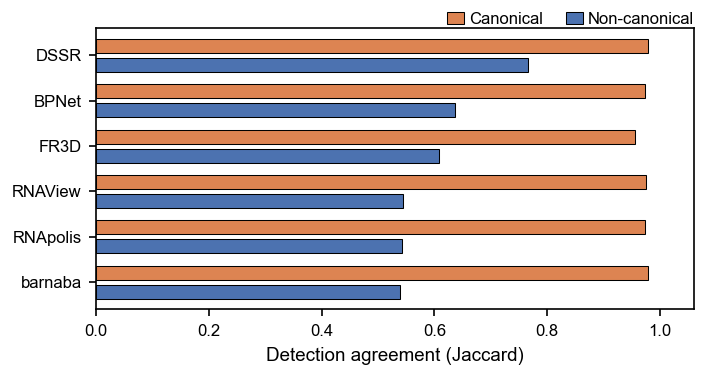

In [4]:
WATSON_CRICK = {frozenset("GC"), frozenset("AU")}


@lru_cache(maxsize=1)
def _residue_names():
    return _json("comparison/residue_names.json")


def _is_canonical(pdb, key, labels):
    names = _residue_names().get(pdb, {})
    bases = [names.get(f"{chain}|{num}|{icode}") for chain, num, icode in key]
    if None in bases or frozenset(bases) not in WATSON_CRICK:
        return False
    return any(part == "cWW" for lw in labels for part in lw.split("|"))


@lru_cache(maxsize=1)
@disk_cached
def _detection_counts():
    pairsets = _load_all_pairsets()
    counts = {}
    for tool, label in zip(MATRIX_TOOLS[1:], MATRIX_LABELS[1:]):
        pdbs = sorted(pairsets["rubric"].keys() & pairsets[tool].keys())
        shared, union = np.zeros((len(pdbs), 2)), np.zeros((len(pdbs), 2))
        n_ambiguous = 0
        for i, pdb in enumerate(pdbs):
            ours, theirs = pairsets["rubric"][pdb], pairsets[tool][pdb]
            for key in ours.keys() | theirs.keys():
                labels = ours.get(key, set()) | theirs.get(key, set())
                if any("|" in lw for lw in labels):
                    n_ambiguous += 1
                    continue
                k = 0 if _is_canonical(pdb, key, labels) else 1
                union[i, k] += 1
                shared[i, k] += key in ours and key in theirs
        counts[label] = (shared, union)
        print(f"{label:9s} ambiguous pairs left out: {n_ambiguous:,}")
    return counts


@lru_cache(maxsize=1)
def rubric_detection_by_type():
    return pd.DataFrame({label: {"canonical": s[:, 0].sum() / u[:, 0].sum(),
                                 "non-canonical": s[:, 1].sum() / u[:, 1].sum()}
                         for label, (s, u) in _detection_counts().items()}).T


@lru_cache(maxsize=None)
@disk_cached
def rubric_detection_ci(kind):
    k = 0 if kind == "canonical" else 1
    return pd.DataFrame({label: dict(zip(("lo", "hi"), bootstrap_ci(
                             lambda w: (w @ s[:, k]) / (w @ u[:, k]), len(s))))
                         for label, (s, u) in _detection_counts().items()}).T


TOOL_ORDER = list(rubric_detection_by_type()["non-canonical"].sort_values(ascending=False).index)
print(rubric_detection_by_type().loc[TOOL_ORDER].round(3))
for _kind in ("canonical", "non-canonical"):
    print(_kind, "95% CI\n", rubric_detection_ci(_kind).loc[TOOL_ORDER].round(3))


def draw_detection(ax):
    draw_split_bars(ax, rubric_detection_by_type(),
                    {kind: rubric_detection_ci(kind) for kind in ("canonical", "non-canonical")},
                    "Detection agreement (Jaccard)")


fig, ax = plt.subplots(figsize=(4.8, 2.6))
draw_detection(ax)
fig.tight_layout()
equalize_pair_gaps(ax)
seat_legend(ax)
save(fig, "figures/main/figure2_B_detection_agreement.png")
plt.show()

rubric_detection_by_type().to_csv(SOURCE_DATA / "figure2_detection_agreement.csv")
for kind in ("canonical", "non-canonical"):
    rubric_detection_ci(kind).to_csv(SOURCE_DATA / f"figure2_detection_ci_{kind}.csv")


## Panel C
Fraction of pairs both tools detect that get the same LW class as RUBRIC, canonical and non-canonical pairs


          canonical  non-canonical
DSSR         0.9982         0.9599
BPNet        0.9998         0.9669
FR3D         0.9993         0.9820
RNAView      0.9964         0.9250
RNApolis     0.9985         0.8775
barnaba      0.9953         0.7920


DSSR        0.9538
BPNet       0.9610
FR3D        0.9787
RNAView     0.9133
RNApolis    0.8547
barnaba     0.7626
Name: kappa, dtype: float64


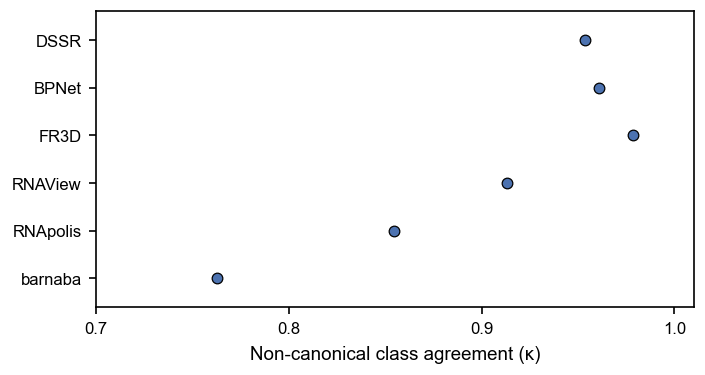

In [5]:
@lru_cache(maxsize=1)
@disk_cached
def _class_counts():
    pairsets = _load_all_pairsets()
    units = {tool: _single_family_units(pairsets[tool]) for tool in MATRIX_TOOLS}
    counts = {}
    for tool, label in zip(MATRIX_TOOLS[1:], MATRIX_LABELS[1:]):
        ours = units["rubric"]
        pdbs = sorted(pairsets["rubric"].keys() & pairsets[tool].keys())
        row = {pdb: i for i, pdb in enumerate(pdbs)}
        same, shared = np.zeros((len(pdbs), 2)), np.zeros((len(pdbs), 2))
        for (pdb, key), a in ours.items():
            b = units[tool].get((pdb, key))
            if b is None or pdb not in row:
                continue
            k = 0 if _is_canonical(pdb, key, {a, b}) else 1
            shared[row[pdb], k] += 1
            same[row[pdb], k] += a == b
        counts[label] = (same, shared)
    return counts


@lru_cache(maxsize=1)
def rubric_class_agreement():
    return pd.DataFrame({label: {"canonical": s[:, 0].sum() / n[:, 0].sum(),
                                 "non-canonical": s[:, 1].sum() / n[:, 1].sum()}
                         for label, (s, n) in _class_counts().items()}).T


@lru_cache(maxsize=None)
@disk_cached
def rubric_class_ci(kind):
    k = 0 if kind == "canonical" else 1
    return pd.DataFrame({label: dict(zip(("lo", "hi"), bootstrap_ci(
                             lambda w: (w @ s[:, k]) / (w @ n[:, k]), len(s))))
                         for label, (s, n) in _class_counts().items()}).T


@lru_cache(maxsize=1)
def rubric_class_kappa():
    """Cohen's kappa between RUBRIC and each tool on the LW class of non-canonical
    pairs both detect; the same computation as the RUBRIC row of Fig. S3B."""
    pairsets = _load_all_pairsets()
    units = {tool: _single_family_units(pairsets[tool]) for tool in MATRIX_TOOLS}
    out = {}
    for tool, label in zip(MATRIX_TOOLS[1:], MATRIX_LABELS[1:]):
        n = agree = 0
        c1, c2 = Counter(), Counter()
        for (pdb, key), a in units["rubric"].items():
            b = units[tool].get((pdb, key))
            if b is None or _is_canonical(pdb, key, {a, b}):
                continue
            n += 1
            agree += a == b
            c1[a] += 1
            c2[b] += 1
        po, pe = agree / n, sum(c1[k] * c2[k] for k in c1) / n ** 2
        out[label] = (po - pe) / (1 - pe)
    return pd.Series(out, name="kappa")


print(rubric_class_agreement().loc[TOOL_ORDER].round(4))
print(rubric_class_kappa().loc[TOOL_ORDER].round(4))


def draw_classification(ax):
    v = rubric_class_kappa().reindex(TOOL_ORDER).to_numpy(float)
    y = np.arange(len(TOOL_ORDER))
    ax.scatter(v, y, s=26, color=BLUE, zorder=3, edgecolors="black", linewidths=0.6)
    ax.set_yticks(y, TOOL_ORDER)
    ax.set_ylim(len(TOOL_ORDER) - 0.4, -0.6)
    ax.set_xlim(0.7, 1.01)
    ax.set_xticks([0.7, 0.8, 0.9, 1.0])
    ax.set_xlabel("Non-canonical class agreement (\u03ba)")
    finish(ax)


fig, ax = plt.subplots(figsize=(4.8, 2.6))
draw_classification(ax)
fig.tight_layout()
save(fig, "figures/main/figure2_C_classification_agreement.png")
plt.show()

rubric_class_agreement().to_csv(SOURCE_DATA / "figure2_classification_agreement.csv")
rubric_class_kappa().to_csv(SOURCE_DATA / "figure2_classification_kappa.csv")
for kind in ("canonical", "non-canonical"):
    rubric_class_ci(kind).to_csv(SOURCE_DATA / f"figure2_classification_ci_{kind}.csv")


## Runtime helpers

In [6]:
SPEED_TOOLS = [
    ("rnapolis", "RNApolis", "#D55E00"), ("barnaba", "barnaba", "#0072B2"),
    ("fr3d", "FR3D", "#E69F00"), ("rnaview", "RNAView", "#56B4E9"),
    ("bpnet", "BPNet", "#009E73"), ("dssr", "DSSR", "#000000")]


def speedups():
    s = pd.read_csv(data_file("benchmark/runtime_direct_all/speedups.csv"))
    return s[s["baseline"] == "rubric"]


N_BINS, MIN_PER_BIN = 12, 30


def size_groups(sp, n_bins=N_BINS, min_per_bin=MIN_PER_BIN):
    structs = sp[["pdb", "nucleotides"]].drop_duplicates()
    log_n = np.log10(structs["nucleotides"].to_numpy())
    edges = np.linspace(log_n.min(), log_n.max(), n_bins + 1)
    idx = np.clip(np.digitize(log_n, edges) - 1, 0, n_bins - 1)
    bins = [[k] for k in range(n_bins) if (idx == k).any()]
    count = lambda b: sum((idx == k).sum() for k in b)
    while len(bins) > 1 and min(count(b) for b in bins) < min_per_bin:
        i = min(range(len(bins)), key=lambda j: count(bins[j]))
        nbrs = [j for j in (i - 1, i + 1) if 0 <= j < len(bins)]
        j = min(nbrs, key=lambda j: count(bins[j]))
        lo, hi = sorted((i, j))
        bins[lo:hi + 1] = [bins[lo] + bins[hi]]
    to_bin = {k: g for g, b in enumerate(bins) for k in b}
    return dict(zip(structs["pdb"], (to_bin[k] for k in idx)))


## Panel A
Absolute runtime against RNA size for every tool

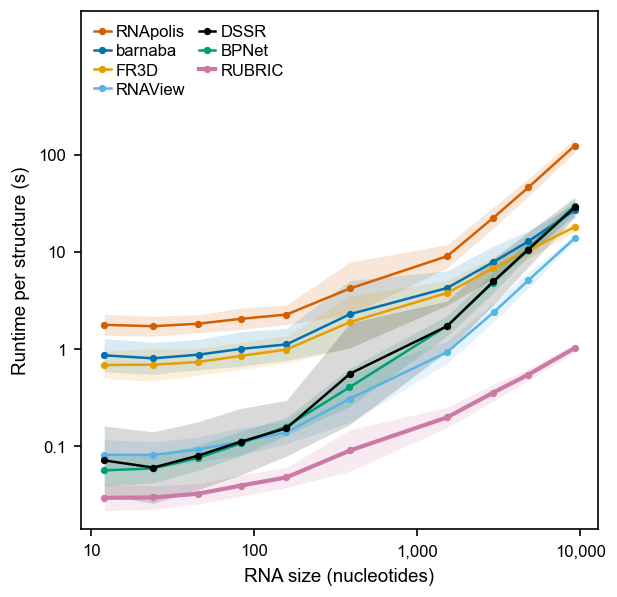

Total runtime over the 2,009 structures every tool completed (min):
RUBRIC        4.3
RNAView      32.4
BPNet        63.7
DSSR         68.7
FR3D         85.3
barnaba     106.9
RNApolis    320.8


In [7]:
RUNTIME_TOOLS = [("rubric", "RUBRIC", "#CC79A7"), *SPEED_TOOLS]


def per_structure_runtimes():
    ps = pd.read_csv(data_file("benchmark/runtime_direct_all/per_structure.csv"))
    ps = ps[(ps["successful"] > 0) & (ps["median_seconds"] > 0)]
    return ps[ps["tool"].isin([t for t, _, _ in RUNTIME_TOOLS])]


def draw_runtime(ax):
    ps = per_structure_runtimes()
    ps = ps.assign(group=ps["pdb"].map(size_groups(speedups())),
                   log_seconds=np.log(ps["median_seconds"]))
    handles = []
    for tool, name, colour in RUNTIME_TOOLS:
        g = ps[ps["tool"] == tool].groupby("group")
        xs = (10 ** g["nucleotides"].apply(lambda n: np.median(np.log10(n)))).to_numpy()
        gmean = np.exp(g["log_seconds"].mean().to_numpy())
        gsd = np.exp(g["log_seconds"].std().to_numpy())
        lw = 2.0 if tool == "rubric" else 1.2
        ax.fill_between(xs, gmean / gsd, gmean * gsd, color=colour, alpha=0.15, lw=0)
        line, = ax.plot(xs, gmean, color=colour, lw=lw, marker="o", ms=2.5, label=name,
                        zorder=4 if tool == "rubric" else 3)
        handles.append((gmean[0], line))
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_ylim(top=3000)
    order = [h for _, h in sorted(handles, key=lambda t: -t[0])]
    ax.legend(handles=order, loc="upper left", ncol=2, handlelength=1.0, handletextpad=0.3,
              columnspacing=0.8, labelspacing=0.25, borderaxespad=0.4, frameon=False)
    ax.xaxis.set_major_locator(FixedLocator([10, 100, 1000, 10000]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.yaxis.set_major_locator(FixedLocator([0.01, 0.1, 1, 10, 100]))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.yaxis.set_minor_locator(plt.NullLocator())
    ax.set_xlabel("RNA size (nucleotides)")
    ax.set_ylabel("Runtime per structure (s)")
    finish(ax)
    ax.set_box_aspect(1)


fig, ax = plt.subplots(figsize=(4.2, 4.2))
draw_runtime(ax)
fig.tight_layout()
save(fig, "figures/main/figure2_A_runtime_absolute.png")
plt.show()

ps = per_structure_runtimes()
common = set.intersection(*(set(ps.loc[ps["tool"] == t, "pdb"]) for t, _, _ in RUNTIME_TOOLS))
totals = pd.Series({name: ps.loc[(ps["tool"] == t) & ps["pdb"].isin(common), "median_seconds"].sum() / 60
                    for t, name, _ in RUNTIME_TOOLS}, name="total_minutes").sort_values()
print(f"Total runtime over the {len(common):,} structures every tool completed (min):")
print(totals.round(1).to_string())
totals.to_csv(SOURCE_DATA / "figure2_runtime_totals.csv")


## Panel F
RUBRIC's ambiguous pairs are the pairs on which the other tools split between classes; unambiguous pairs are weighted to the same classes


2,015 ambiguous and 751,920 unambiguous RUBRIC pairs in 1,177 structures; 744,286 annotated by at least two other tools
class split among other tools: ambiguous 62.5% vs class-matched unambiguous 23.4%; cluster-robust P = 8.8e-264


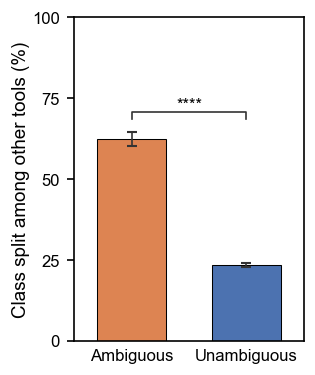

In [8]:
from scipy.stats import norm

OTHER = ["dssr", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]


def family(labels):
    fams = {_canon_lw(lw) for lw in labels if len(lw) == 3 and lw[0] in "ct"
            and lw[1] in "WHS" and lw[2] in "WHS"}
    return next(iter(fams)) if len(fams) == 1 else None


@lru_cache(maxsize=1)
@disk_cached
def votes_table():
    pairsets = _load_all_pairsets()
    rows = []
    for pdb, pairs in pairsets["rubric"].items():
        for key, labels in pairs.items():
            amb = [lw for lw in labels if "|" in lw]
            own = None if amb else family(labels)
            if not amb and own is None:
                continue
            opts = tuple(sorted({_canon_lw(x) for x in amb[0].split("|")})) if amb else None
            votes = {t: f for t in OTHER
                     if (lab := pairsets[t].get(pdb, {}).get(key)) is not None
                     and (f := family(lab)) is not None}
            rows.append((pdb, bool(amb), own, opts, votes))
    return pd.DataFrame(rows, columns=["pdb", "amb", "own", "opts", "votes"])


V = votes_table().copy()
V["k"] = V.votes.map(len)
V["split"] = V.votes.map(lambda v: len(set(v.values())) > 1)
E = V[V.k >= 2].reset_index(drop=True)
print(f"{V.amb.sum():,} ambiguous and {(~V.amb).sum():,} unambiguous RUBRIC pairs in "
      f"{V.pdb.nunique():,} structures; {len(E):,} annotated by at least two other tools")

B_REPS = 2000
pdb_idx, pdbs = pd.factorize(E.pdb)
nP = len(pdbs)


def counts(mask):
    m = np.asarray(mask)
    return (np.bincount(pdb_idx[m], weights=E.split.to_numpy()[m].astype(float), minlength=nP),
            np.bincount(pdb_idx[m], minlength=nP).astype(float))


UN_FAM = {f: counts((~E.amb) & (E.own == f)) for f in E.loc[~E.amb, "own"].unique()}
ALL_AMB = counts(E.amb)
W_ALL = Counter()
for o in E[E.amb].opts:
    for f in o:
        W_ALL[f] += 1 / len(o)


def matched(w, weights):
    r = {f: (w @ UN_FAM[f][0]) / (w @ UN_FAM[f][1]) for f in weights if f in UN_FAM}
    return sum(r[f] * weights[f] for f in r) / sum(weights[f] for f in r)


def stats(w):
    return {"all_amb": (w @ ALL_AMB[0]) / (w @ ALL_AMB[1]), "all_matched": matched(w, W_ALL)}


POINT2 = stats(np.ones(nP))
rng = np.random.default_rng(7)
BS = pd.DataFrame([stats(np.bincount(rng.integers(0, nP, nP), minlength=nP).astype(float))
                   for _ in range(B_REPS)])


def ci(k):
    return BS[k].quantile(0.025), BS[k].quantile(0.975)


def stars(p):
    return ("****" if p < 0.0001 else "***" if p < 0.001 else "**" if p < 0.01
            else "*" if p < 0.05 else "n.s.")


def cluster_p(weights, amb_counts):
    fams = [f for f in weights if f in UN_FAM]
    wsum = sum(weights[f] for f in fams)
    d_a, n_a = amb_counts
    r_a = d_a.sum() / n_a.sum()
    diff = r_a
    u = (d_a - r_a * n_a) / n_a.sum()
    for f in fams:
        d_f, n_f = UN_FAM[f]
        r_f = d_f.sum() / n_f.sum()
        wf = weights[f] / wsum
        diff -= wf * r_f
        u -= wf * (d_f - r_f * n_f) / n_f.sum()
    G = len(u)
    se = np.sqrt(G / (G - 1) * (u ** 2).sum())
    return 2 * norm.sf(abs(diff / se))


P_AMB = cluster_p(dict(W_ALL), ALL_AMB)
print(f"class split among other tools: ambiguous {100 * POINT2['all_amb']:.1f}% vs class-matched "
      f"unambiguous {100 * POINT2['all_matched']:.1f}%; cluster-robust P = {P_AMB:.2g}")
pd.DataFrame([{"group": "ambiguous", "split_pct": 100 * POINT2["all_amb"],
               "ci_lo": 100 * ci("all_amb")[0], "ci_hi": 100 * ci("all_amb")[1]},
              {"group": "unambiguous (class-matched)", "split_pct": 100 * POINT2["all_matched"],
               "ci_lo": 100 * ci("all_matched")[0], "ci_hi": 100 * ci("all_matched")[1]}]
             ).to_csv(SOURCE_DATA / "figure2_F_ambiguity.csv", index=False)


def _vbar(ax, x, key, colour, w):
    v = 100 * POINT2[key]; lo, hi = (100 * c for c in ci(key))
    ax.bar(x, v, w, color=colour, edgecolor="black", linewidth=0.5)
    ax.errorbar(x, v, yerr=[[v - lo], [hi - v]], fmt="none", ecolor="0.2", capsize=2.5, lw=0.8)
    return hi


def draw_ambiguity(ax):
    w = 0.6
    ya = _vbar(ax, 0, "all_amb", ORANGE, w)
    ym = _vbar(ax, 1, "all_matched", BLUE, w)
    y = max(ya, ym) + 4
    ax.plot([0, 0, 1, 1], [y, y + 2.0, y + 2.0, y], color="0.2", lw=0.8)
    ax.text(0.5, y + 2.0, stars(P_AMB), ha="center", va="bottom", fontsize=8)
    ax.set_xticks([0, 1], ["Ambiguous", "Unambiguous"])
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(0, 100)
    ax.set_yticks([0, 25, 50, 75, 100])
    ax.set_ylabel("Class split among other tools (%)", labelpad=1)
    finish(ax)
    ax.tick_params(axis="x", length=0)


fig, ax = plt.subplots(figsize=(2.2, 2.6))
draw_ambiguity(ax)
fig.tight_layout()
save(fig, "figures/main/figure2_F_ambiguity.png")
plt.show()


## Combined figure


saved 6.73 x 4.79 in; at 6.73 in wide the smallest text prints at 7.00 pt, height 4.79 in


text 7.0 pt, axis titles 8.5 pt, panel letters 12.0 pt at 6.73 in (6.73 in saved)


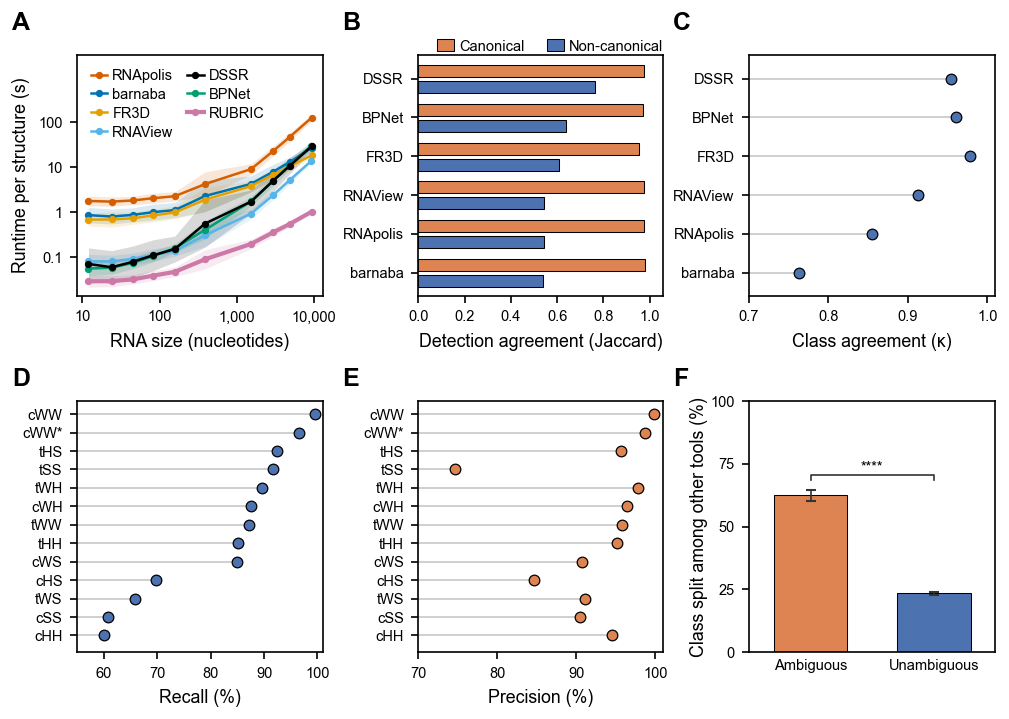

In [9]:
FIG_W, FIG_H = 6.73, 4.75
fig = plt.figure(figsize=(FIG_W, FIG_H))
MARGIN, GAP_X, GAP_Y, TOP = 0.08, 0.04, 0.30, 0.22     # MARGIN 0.08 + save pad 0.08: saved at the 6.73 in RSC width
CW = (FIG_W - 2 * MARGIN - 2 * GAP_X) / 3
CH = (FIG_H - TOP - MARGIN - GAP_Y) / 2
CELLS = [(MARGIN + c * (CW + GAP_X), TOP + r * (CH + GAP_Y)) for r in range(2) for c in range(3)]
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
AXES = [fig.add_axes(inch(x + 0.6, y + 0.2, CW - 0.7, CH - 0.6)) for x, y in CELLS]
ax_a, ax_b, ax_c, ax_d, ax_e, ax_f = AXES

draw_runtime(ax_a)
draw_detection(ax_b)
draw_classification(ax_c)
draw_recall_precision(ax_d, ax_e)
draw_ambiguity(ax_f)


def guide_lines(ax):
    """Thin grey line from the left axis to each dot (combined figure only)."""
    x0 = ax.get_xlim()[0]
    for coll in list(ax.collections):
        for x, y in coll.get_offsets():
            ax.hlines(y, x0, x, color="0.78", lw=0.8, zorder=1)


for ax in (ax_c, ax_d, ax_e):
    guide_lines(ax)
for ax in AXES:
    ax.set_box_aspect(None)
ys = _row_positions(len(A_CLASSES))
for ax in (ax_d, ax_e):
    ax.set_yticks(ys, A_LABELS)
    ax.tick_params(labelleft=True)

TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


set_uniform_text(fig)
enlarge_axis_labels(fig)
ax_f.tick_params(axis="x", length=0)
ax_c.set_xlabel("Class agreement (\u03ba)")
for t in ax_f.texts:
    t.set_fontsize(10)

# fit each plot (frame + labels + legend) to its equal cell
for _ in range(12):
    seat_legend(ax_b)
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    for ax, (x, y) in zip(AXES, CELLS):
        bb, p = ax.get_tightbbox(r), ax.get_position()
        bx0, bx1 = bb.x0 / fig.dpi, bb.x1 / fig.dpi
        bt, bbot = FIG_H - bb.y1 / fig.dpi, FIG_H - bb.y0 / fig.dpi
        ax_x, ax_w = p.x0 * FIG_W + x - bx0, p.width * FIG_W + CW - (bx1 - bx0)
        ax_t, ax_h = FIG_H - (p.y0 + p.height) * FIG_H + y - bt, p.height * FIG_H + CH - (bbot - bt)
        ax.set_position(inch(ax_x, ax_t, ax_w, ax_h))
# same frame top/bottom across each row, same left/right edges down each column
rows = ((ax_a, ax_b, ax_c), (ax_d, ax_e, ax_f))
for row in rows:
    ps = [a.get_position() for a in row]
    b, t = max(p.y0 for p in ps), min(p.y0 + p.height for p in ps)
    for a in row:
        p = a.get_position()
        a.set_position([p.x0, b, p.width, t - b])
for top, bot in ((ax_a, ax_d), (ax_b, ax_e), (ax_c, ax_f)):
    pt, pb = top.get_position(), bot.get_position()
    x0, x1 = max(pt.x0, pb.x0), min(pt.x1, pb.x1)
    for a, p in ((top, pt), (bot, pb)):
        a.set_position([x0, p.y0, x1 - x0, p.height])
seat_legend(ax_b)
equalize_pair_gaps(ax_b)

fig.canvas.draw()
r = fig.canvas.get_renderer()
inv = fig.transFigure.inverted()
bbox = lambda ax: ax.get_tightbbox(r).transformed(inv)
col_x = [min(bbox(t).x0, bbox(b).x0) for t, b in ((ax_a, ax_d), (ax_b, ax_e), (ax_c, ax_f))]
row_y = [max(bbox(a).y1 for a in row) for row in rows]
for i, s in enumerate("ABCDEF"):
    fig.text(col_x[i % 3], row_y[i // 3] + 0.03 / FIG_H, s, fontsize=LETTER_PT,
             fontweight="bold", ha="left", va="bottom")


def _ensure_print_pt(fig, min_pt=7.0, page_in=6.73, pad=0.08):
    import matplotlib.text as mtext
    texts = [t for t in fig.findobj(mtext.Text) if t.get_visible() and t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        smallest = min(t.get_fontsize() for t in texts) / shrink
        if smallest >= min_pt - 1e-3:
            break
        for t in texts:
            t.set_fontsize(t.get_fontsize() * min_pt / smallest * 1.005)
    print(f"saved {bb.width + 2 * pad:.2f} x {bb.height + 2 * pad:.2f} in; at {page_in} in wide "
          f"the smallest text prints at {smallest:.2f} pt, height {(bb.height + 2 * pad) / shrink:.2f} in")


_ensure_print_pt(fig)
def _enforce_print_spec(fig, text_pt=7.0, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    """Ticks and other text at text_pt, axis titles at axis_pt, panel letters at letter_pt, as printed at page_in wide."""
    import matplotlib.text as mtext
    axis = {id(lab) for ax in fig.axes for lab in (ax.xaxis.label, ax.yaxis.label)}
    letters = {id(t) for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)}
    texts = [t for t in fig.findobj(mtext.Text) if t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for t in texts:
            t.set_fontsize((letter_pt if id(t) in letters else axis_pt if id(t) in axis else text_pt) * shrink)
    print(f"text {text_pt} pt, axis titles {axis_pt} pt, panel letters {letter_pt} pt at {page_in} in "
          f"({bb.width + 2 * pad:.2f} in saved)")


_enforce_print_spec(fig)
save(fig, "figures/main/figure2.png")
plt.show()
